# Tối ưu HGB rồi kiểm tra lại HCO, VNLS và HCO+VNLS

**Ngày chạy: 13/09/2026.**

Notebook này trả lời hai câu hỏi theo đúng thứ tự:

1. Tuning HistGradientBoosting có làm baseline tốt hơn cấu hình hiện tại không?
2. Khi dùng cùng HGB đã tuning, HCO+VNLS có tốt hơn HCO và VNLS trong cùng ngân sách không?

Nguyên tắc: random search và optimizer chỉ dùng train + inner GroupKFold. Validation dùng để kiểm tra ngoài quá trình tìm kiếm. Test không được đọc trong notebook này.


## 1. Đọc dữ liệu và khóa split

Sử dụng dữ liệu đã sửa ở cutoff 50%. Cùng `id_student` chỉ xuất hiện trong một tập để tránh leakage.


In [1]:
from pathlib import Path
import sys
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, recall_score, f1_score, brier_score_loss
from sklearn.model_selection import GroupKFold, ParameterSampler

ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists() and (ROOT.parent / 'clht_code').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from clht_code.models import ModelConfig, configs, feature_columns, make_pipeline
from clht_code.evaluation import split_groups, metric_table, risk_probability
from clht_code.optimizers import MaskObjective, run_search_budgeted

OUT = ROOT / 'ket_qua'
OUT.mkdir(exist_ok=True)
asof_path = OUT / 'du_lieu_cutoff_50.csv'
if asof_path.exists():
    frame = pd.read_csv(asof_path)
else:
    frame = create_asof(DATA, 0.5, 'fraction', 'strict')
    frame.to_csv(asof_path, index=False, encoding='utf-8-sig')
feature_cols = feature_columns(frame)
X = frame[feature_cols].copy()
y = frame['risk'].astype(int).to_numpy()
train_idx, validation_idx, test_idx = split_groups(frame, seed=41)
X_train, X_validation = X.iloc[train_idx], X.iloc[validation_idx]
y_train, y_validation = y[train_idx], y[validation_idx]
groups_train = frame.iloc[train_idx]['id_student'].to_numpy()
assert not (set(frame.iloc[train_idx].id_student) & set(frame.iloc[validation_idx].id_student))
print({'rows':len(frame),'features':len(feature_cols),'train':len(train_idx),'validation':len(validation_idx),'test_locked':len(test_idx)})


{'rows': 24599, 'features': 27, 'train': 17246, 'validation': 3684, 'test_locked': 3669}


## 2. Hàm đánh giá inner GroupKFold

Mỗi cấu hình được fit lại preprocessing trong từng fold. AP là metric chọn cấu hình; Recall, F1, Brier và thời gian được lưu để thấy trade-off.


In [2]:
def evaluate_config_cv(frame_x, target, groups, config, splits=3):
    fold_rows = []
    started = time.perf_counter()
    for fold, (fit_idx, score_idx) in enumerate(GroupKFold(n_splits=splits).split(frame_x, target, groups), start=1):
        pipeline = make_pipeline(frame_x.iloc[fit_idx], config)
        pipeline.fit(frame_x.iloc[fit_idx], target[fit_idx])
        probabilities = risk_probability(pipeline, frame_x.iloc[score_idx])
        predictions = (probabilities >= 0.5).astype(int)
        fold_rows.append({
            'fold': fold,
            'ap': average_precision_score(target[score_idx], probabilities),
            'recall': recall_score(target[score_idx], predictions, zero_division=0),
            'f1': f1_score(target[score_idx], predictions, zero_division=0),
            'brier': brier_score_loss(target[score_idx], probabilities),
        })
    folds = pd.DataFrame(fold_rows)
    return {
        'mean_ap_cv': folds.ap.mean(), 'std_ap_cv': folds.ap.std(ddof=1),
        'mean_recall_cv': folds.recall.mean(), 'mean_f1_cv': folds.f1.mean(),
        'mean_brier_cv': folds.brier.mean(), 'cv_seconds': time.perf_counter() - started
    }


## 3. Random search cho HistGradientBoosting

Cấu hình baseline hiện tại được chạy lại trong cùng inner-CV. Sau đó thử 12 cấu hình lấy mẫu có seed cố định. `early_stopping=False` để không tạo validation ngẫu nhiên làm phá group split.


In [3]:
baseline_params = {
    'learning_rate': 0.08, 'max_iter': 160, 'max_leaf_nodes': 15,
    'max_depth': None, 'min_samples_leaf': 20, 'l2_regularization': 0.0,
    'max_features': 1.0, 'class_weight': None
}
search_space = {
    'learning_rate': [0.03, 0.05, 0.08, 0.12],
    'max_iter': [120, 200, 300, 450],
    'max_leaf_nodes': [7, 15, 31],
    'max_depth': [None, 3, 5],
    'min_samples_leaf': [10, 20, 40, 80],
    'l2_regularization': [0.0, 0.1, 1.0, 5.0, 10.0],
    'max_features': [0.7, 0.85, 1.0],
    'class_weight': [None, 'balanced'],
}
candidates = [('baseline', baseline_params)]
for index, params in enumerate(ParameterSampler(search_space, n_iter=12, random_state=2026), start=1):
    candidates.append((f'random_{index:02d}', params))

search_rows = []
for candidate_name, params in candidates:
    estimator = HistGradientBoostingClassifier(**params, early_stopping=False, random_state=41)
    config = ModelConfig(f'HGB_{candidate_name}', estimator)
    scores = evaluate_config_cv(X_train, y_train, groups_train, config)
    search_rows.append({'candidate':candidate_name, **params, **scores})
    print(candidate_name, round(scores['mean_ap_cv'], 4), round(scores['mean_recall_cv'], 4), round(scores['cv_seconds'], 2))

hgb_search = pd.DataFrame(search_rows).sort_values(['mean_ap_cv','mean_brier_cv'], ascending=[False,True]).reset_index(drop=True)
hgb_search['rank_ap'] = np.arange(1, len(hgb_search)+1)
hgb_search.to_csv(OUT / 'tim_tham_so_hgb_ngau_nhien.csv', index=False, encoding='utf-8-sig')
display(hgb_search.round(5))


baseline 0.838 0.621 4.36


random_01 0.8366 0.5798 1.59


random_02 0.8363 0.6758 2.5


random_03 0.8347 0.6305 6.02


random_04 0.8369 0.6324 13.27


random_05 0.8404 0.704 4.28


... (4 outputs left out)

random_10 0.836 0.6923 8.19


random_11 0.8346 0.6948 8.62


random_12 0.8374 0.594 2.69


,candidate,learning_rate,max_iter,max_leaf_nodes,max_depth,min_samples_leaf,l2_regularization,max_features,class_weight,mean_ap_cv,std_ap_cv,mean_recall_cv,mean_f1_cv,mean_brier_cv,cv_seconds,rank_ap
0,random_05,0.08,450,7,3.0,10,5.0,1.00,balanced,0.84041,0.00435,0.70405,0.72785,0.13894,4.27677,1
1,random_09,0.03,300,15,NaN,10,0.0,0.70,None,0.83965,0.00302,0.61372,0.71040,0.13324,5.56888,2
2,random_06,0.03,300,15,3.0,10,10.0,0.85,balanced,0.83848,0.00313,0.68261,0.72360,0.14062,3.40965,3
3,baseline,0.08,160,15,NaN,20,0.0,1.00,None,0.83802,0.00277,0.62103,0.71074,0.13395,4.35560,4
4,random_12,0.03,120,15,NaN,80,10.0,0.70,None,0.83736,0.00252,0.59396,0.70048,0.13484,2.69186,5
5,random_08,0.03,200,31,3.0,20,0.1,1.00,None,0.83690,0.00263,0.58008,0.69484,0.13504,2.49141,6
6,random_04,0.05,450,31,NaN,20,5.0,0.70,None,0.83688,0.00253,0.63245,0.71281,0.13514,13.26849,7
7,random_01,0.05,120,7,3.0,20,0.1,0.70,None,0.83664,0.00242,0.57976,0.69525,0.13517,1.59249,8
8,random_02,0.03,120,31,5.0,40,0.0,0.85,balanced,0.83625,0.00183,0.67581,0.72019,0.14228,2.49673,9
9,random_07,0.03,200,7,3.0,80,10.0,1.00,None,0.83610,0.00251,0.57913,0.69386,0.13544,2.36067,10


## 4. Khóa cấu hình tốt nhất bằng inner-CV và kiểm tra validation

Validation không dùng để chọn trong 12 cấu hình; nó chỉ kiểm tra xem cải thiện inner-CV có chuyển sang dữ liệu ngoài search hay không.


In [4]:
parameter_names = list(search_space.keys())
best_row = hgb_search.iloc[0]
best_params = {name: best_row[name] for name in parameter_names}
for key in ['max_iter','max_leaf_nodes','min_samples_leaf']:
    best_params[key] = int(best_params[key])
if pd.isna(best_params['max_depth']):
    best_params['max_depth'] = None
else:
    best_params['max_depth'] = int(best_params['max_depth'])
if pd.isna(best_params['class_weight']):
    best_params['class_weight'] = None

baseline_config = ModelConfig('HGB_baseline', HistGradientBoostingClassifier(**baseline_params, early_stopping=False, random_state=41))
tuned_config = ModelConfig('HGB_tuned', HistGradientBoostingClassifier(**best_params, early_stopping=False, random_state=41))
validation_rows = []
for config, params in [(baseline_config, baseline_params), (tuned_config, best_params)]:
    started = time.perf_counter()
    pipeline = make_pipeline(X_train, config)
    pipeline.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - started
    probabilities = risk_probability(pipeline, X_validation)
    metrics = metric_table(y_validation, probabilities, threshold=0.5)
    validation_rows.append({'model':config.name, **metrics, 'fit_seconds':fit_seconds, 'params':json.dumps(params, ensure_ascii=False)})
validation_comparison = pd.DataFrame(validation_rows)
validation_comparison.to_csv(OUT / 'so_sanh_hgb_co_so_va_toi_uu.csv', index=False, encoding='utf-8-sig')
display(validation_comparison[['model','accuracy','precision_risk','recall_risk','f1_risk','weighted_f1','average_precision_risk','brier_score','fit_seconds']].round(5))
print('Best parameters:', best_params)


,model,accuracy,precision_risk,recall_risk,f1_risk,weighted_f1,average_precision_risk,brier_score,fit_seconds
0,HGB_baseline,0.81813,0.84645,0.63362,0.72473,0.81151,0.85417,0.12843,1.05377
1,HGB_tuned,0.80646,0.76055,0.71193,0.73544,0.80511,0.85322,0.13462,1.56603


Best parameters: {'learning_rate': 0.08, 'max_iter': 450, 'max_leaf_nodes': 7, 'max_depth': 3, 'min_samples_leaf': 10, 'l2_regularization': 5.0, 'max_features': 1.0, 'class_weight': 'balanced'}


## 5. Chạy lại HCO, VNLS và HCO+VNLS bằng HGB đã tuning

Ba phương pháp dùng cùng `alpha=0.85`, ngân sách 12 objective calls và ba seed. Mỗi mask được tìm trên train/inner-CV; validation chỉ chấm nghiệm cuối.


In [5]:
optimizer_rows = []
for method in ['HCO','VNLS','HCO-VNLS']:
    for seed in [41,77,123]:
        objective = MaskObjective(X_train, y_train, groups_train, tuned_config, alpha=0.85)
        search = run_search_budgeted(method, objective, seed=seed, budget=12, population=4)
        selected = search['selected_columns']
        pipeline = make_pipeline(X_train[selected], tuned_config)
        pipeline.fit(X_train[selected], y_train)
        probabilities = risk_probability(pipeline, X_validation[selected])
        metrics = metric_table(y_validation, probabilities, threshold=0.5)
        optimizer_rows.append({
            'method':method,'seed':seed,'alpha':0.85,'budget':12,
            'selected_count':search['selected_count'],'fitness_cv':search['fitness_cv'],
            'ap_cv':search['average_precision_cv'],'validation_ap':metrics['average_precision_risk'],
            'validation_precision':metrics['precision_risk'],'validation_recall':metrics['recall_risk'],
            'validation_f1':metrics['f1_risk'],'validation_weighted_f1':metrics['weighted_f1'],
            'validation_brier':metrics['brier_score'],'search_seconds':search['wall_seconds'],
            'selected_columns':'|'.join(selected)
        })
        print(method, seed, search['selected_count'], round(metrics['average_precision_risk'],4))
optimizer_tuned = pd.DataFrame(optimizer_rows)
optimizer_tuned.to_csv(OUT / 'ket_qua_hco_vnls_tren_hgb_toi_uu.csv', index=False, encoding='utf-8-sig')
display(optimizer_tuned.round(5))


HCO 41 13 0.8443


HCO 77 14 0.8486


HCO 123 14 0.8449


VNLS 41 12 0.8366


VNLS 77 11 0.8121


VNLS 123 16 0.8434


HCO-VNLS 41 10 0.8415


HCO-VNLS 77 14 0.8486


HCO-VNLS 123 10 0.8154


,method,seed,alpha,budget,selected_count,fitness_cv,ap_cv,validation_ap,validation_precision,validation_recall,validation_f1,validation_weighted_f1,validation_brier,search_seconds,selected_columns
0,HCO,41,0.85,12,13,0.78454,0.83148,0.84430,0.76258,0.69684,0.72823,0.80155,0.13891,45.94320,code_module|gender|imd_band|date_registration|...
1,HCO,77,0.85,12,14,0.78100,0.83386,0.84864,0.75814,0.70259,0.72931,0.80133,0.13694,42.07980,code_module|region|imd_band|age_band|studied_c...
2,HCO,123,0.85,12,14,0.77599,0.82796,0.84493,0.75509,0.69325,0.72285,0.79728,0.13964,42.66537,code_module|imd_band|age_band|num_of_prev_atte...
3,VNLS,41,0.85,12,12,0.78612,0.82680,0.83664,0.75920,0.68175,0.71840,0.79565,0.14293,38.78931,code_module|region|num_of_prev_attempts|studie...
4,VNLS,77,0.85,12,11,0.77429,0.80635,0.81215,0.75000,0.65302,0.69816,0.78330,0.15292,35.61550,num_of_prev_attempts|cutoff_day|progress_fract...
5,VNLS,123,0.85,12,16,0.76935,0.83323,0.84345,0.74554,0.69037,0.71690,0.79228,0.13953,43.67082,code_presentation|gender|highest_education|imd...
6,HCO-VNLS,41,0.85,12,10,0.79985,0.82989,0.84151,0.75369,0.69684,0.72415,0.79772,0.14038,41.60824,code_module|gender|imd_band|date_registration|...
7,HCO-VNLS,77,0.85,12,14,0.78100,0.83386,0.84864,0.75814,0.70259,0.72931,0.80133,0.13694,39.82959,code_module|region|imd_band|age_band|studied_c...
8,HCO-VNLS,123,0.85,12,10,0.78095,0.80766,0.81536,0.74675,0.66092,0.70122,0.78429,0.15189,38.87076,code_module|imd_band|age_band|studied_credits|...


In [6]:
optimizer_summary = (optimizer_tuned.groupby('method')
    .agg(mean_validation_ap=('validation_ap','mean'), std_validation_ap=('validation_ap','std'),
         mean_validation_recall=('validation_recall','mean'), mean_validation_f1=('validation_f1','mean'),
         mean_validation_weighted_f1=('validation_weighted_f1','mean'), mean_validation_brier=('validation_brier','mean'),
         mean_fitness=('fitness_cv','mean'), mean_features=('selected_count','mean'), mean_search_seconds=('search_seconds','mean'))
    .reset_index())
optimizer_summary.to_csv(OUT / 'tong_hop_hco_vnls_tren_hgb_toi_uu.csv', index=False, encoding='utf-8-sig')
display(optimizer_summary.sort_values('mean_validation_ap', ascending=False).round(5))

previous_path = OUT / 'tong_hop_hco_vnls_theo_mo_hinh.csv'
if previous_path.exists():
    previous = pd.read_csv(previous_path)
    previous = previous[previous.model == 'HistGradientBoosting'][['method','mean_validation_ap','mean_validation_recall','mean_validation_weighted_f1','mean_fitness','mean_features']]
    comparison = previous.merge(optimizer_summary, on='method', suffixes=('_baseline_hgb','_tuned_hgb'))
    comparison['delta_ap'] = comparison['mean_validation_ap_tuned_hgb'] - comparison['mean_validation_ap_baseline_hgb']
    comparison['delta_recall'] = comparison['mean_validation_recall_tuned_hgb'] - comparison['mean_validation_recall_baseline_hgb']
    comparison['delta_weighted_f1'] = comparison['mean_validation_weighted_f1_tuned_hgb'] - comparison['mean_validation_weighted_f1_baseline_hgb']
    comparison.to_csv(OUT / 'so_sanh_hgb_toi_uu_va_co_so.csv', index=False, encoding='utf-8-sig')
    display(comparison.round(5))


,method,mean_validation_ap,std_validation_ap,mean_validation_recall,mean_validation_f1,mean_validation_weighted_f1,mean_validation_brier,mean_fitness,mean_features,mean_search_seconds
0,HCO,0.84595,0.00235,0.69756,0.72679,0.80005,0.13850,0.78051,13.66667,43.56279
1,HCO-VNLS,0.83517,0.01752,0.68678,0.71823,0.79445,0.14307,0.78727,11.33333,40.10286
2,VNLS,0.83074,0.01646,0.67505,0.71115,0.79041,0.14513,0.77659,13.00000,39.35854


,method,mean_validation_ap_baseline_hgb,mean_validation_recall_baseline_hgb,mean_validation_weighted_f1_baseline_hgb,mean_fitness_baseline_hgb,mean_features_baseline_hgb,mean_validation_ap_tuned_hgb,std_validation_ap,mean_validation_recall_tuned_hgb,mean_validation_f1,mean_validation_weighted_f1_tuned_hgb,mean_validation_brier,mean_fitness_tuned_hgb,mean_features_tuned_hgb,mean_search_seconds,delta_ap,delta_recall,delta_weighted_f1
0,HCO,0.83466,0.59579,0.79712,0.77944,12.66667,0.84595,0.00235,0.69756,0.72679,0.80005,0.13850,0.78051,13.66667,43.56279,0.01129,0.10177,0.00293
1,HCO-VNLS,0.83477,0.59626,0.79768,0.78663,11.33333,0.83517,0.01752,0.68678,0.71823,0.79445,0.14307,0.78727,11.33333,40.10286,0.00040,0.09052,-0.00323
2,VNLS,0.83182,0.59363,0.79849,0.77654,13.00000,0.83074,0.01646,0.67505,0.71115,0.79041,0.14513,0.77659,13.00000,39.35854,-0.00107,0.08142,-0.00808


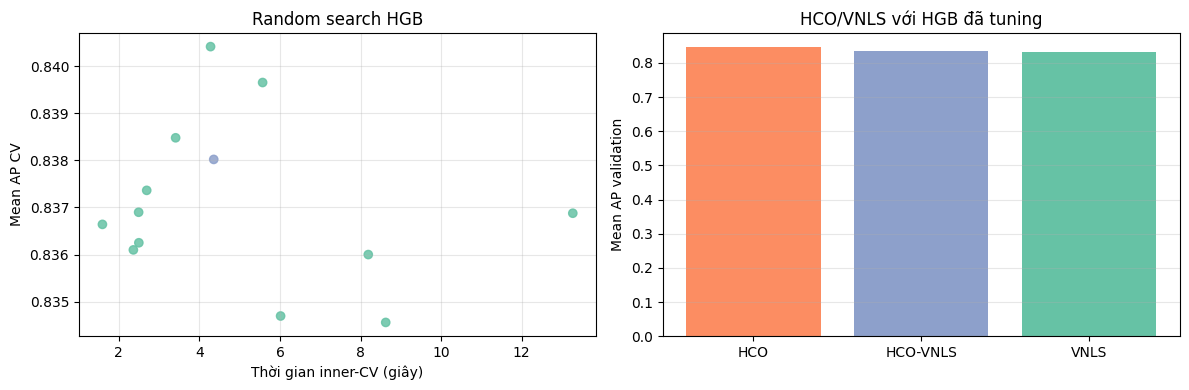

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
colors = ['#8da0cb' if name == 'baseline' else '#66c2a5' for name in hgb_search.candidate]
axes[0].scatter(hgb_search.cv_seconds, hgb_search.mean_ap_cv, c=colors, alpha=0.85)
axes[0].set(xlabel='Thời gian inner-CV (giây)', ylabel='Mean AP CV', title='Random search HGB')
axes[0].grid(True, alpha=0.3)
axes[1].bar(optimizer_summary.method, optimizer_summary.mean_validation_ap, color=['#fc8d62','#8da0cb','#66c2a5'])
axes[1].set(ylabel='Mean AP validation', title='HCO/VNLS với HGB đã tuning')
axes[1].grid(True, axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / 'toi_uu_hgb_va_hco_vnls.png', dpi=160)
plt.show()


## 6. Quy tắc kết luận

- HGB được coi là tối ưu hơn chỉ khi AP validation tăng so với baseline; nếu inner-CV tăng nhưng validation giảm thì không giữ cấu hình đó.
- HCO+VNLS được coi là có lợi khi AP/Recall/fitness tăng lặp lại qua seed trong cùng budget; nếu chỉ giảm feature thì ghi là cải thiện độ gọn.
- Notebook này chưa đọc test. Nếu có ứng viên tốt hơn, bước sau phải khóa cấu hình rồi mới chạy test một lần.
